# 02 · Denoising features and model analysis

**Question.** What information reaches the fusion and residual MLP, and how did validation choose a configuration?  
**Data boundary.** Feature pictures and residual distributions use **train** only. Validation CSVs document choices already made. Final test CSVs are read only as locked outcomes; they never drive a change here.  
**Outputs.** Feature visualizations and model-selection plots in `notebooks/figures/`.

## Setup and saved configuration

Load the same preprocessing and feature functions as the experiment, plus the frozen NLM and fusion parameters. Nothing is retrained in this notebook.

In [1]:
from pathlib import Path
import csv, hashlib, json, sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/manifest.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run the notebook from mini-project/ or a child folder")
sys.path.insert(0, str(ROOT))
from src.core import noisy_image, filters, features, psnr

manifest = json.loads((ROOT / "data/manifest.json").read_text(encoding="utf-8"))
splits = manifest["splits"]
FIG = ROOT / "notebooks/figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 302
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
def image(split, image_id):
    value = cv2.imread(str(ROOT / "data/clean" / split / f"{image_id}.png"), cv2.IMREAD_GRAYSCALE)
    if value is None:
        raise FileNotFoundError(f"Missing image: {split}/{image_id}")
    return value
print("Project:", ROOT.name, "| seed:", SEED, "| source:", manifest["source_dataset"])

from src.learn import ResidualMLP
run = json.loads((ROOT / "results/run.json").read_text(encoding="utf-8"))
h_map = {int(k): float(v) for k, v in run["selected_nlm_h"].items()}
fusion = json.loads((ROOT / "models/fusion.json").read_text(encoding="utf-8"))
model, stored_h, texture = ResidualMLP.load(ROOT / "models/denoiser.npz")
assert h_map == stored_h
print("NLM h by σ:", h_map, "| fusion weights:", fusion)
print("MLP input dimensions:", len(model.mean), "| hidden units:", len(model.weights["b1"]), "| texture:", texture)

Project: mini-project | seed: 302 | source: Berkeley Segmentation Dataset BSDS300, images archive
NLM h by σ: {15: 16.0, 25: 24.0, 50: 40.0} | fusion weights: {'15': [0.1, 0.4, 0.5], '25': [0.25, 0.25, 0.5], '50': [0.45, 0.05, 0.5]}
MLP input dimensions: 10 | hidden units: 32 | texture: True


## One train image through the filter bank

Gaussian averages nearby pixels, bilateral also checks intensity similarity, and NLM looks for similar patches. All receive exactly the same synthetic noisy input.

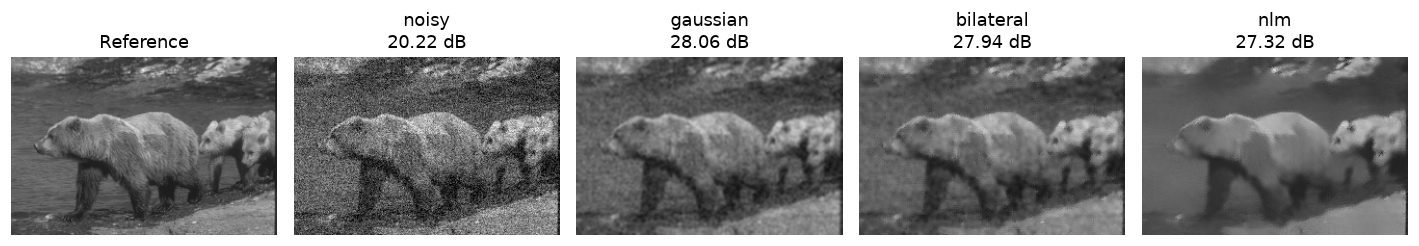

In [2]:
sigma = 25
image_id = splits["train"][0]
clean = image("train", image_id)
noisy = noisy_image(clean, sigma, image_id, SEED)
outputs = filters(noisy, h_map[sigma], sigma)
fig, axes = plt.subplots(1, 5, figsize=(13, 3.2))
for ax, (label, pixels) in zip(axes, [("Reference", clean), *outputs.items()]):
    ax.imshow(pixels, cmap="gray", vmin=0, vmax=255)
    ax.set_title(label if label == "Reference" else f"{label}\n{psnr(clean,pixels):.2f} dB")
    ax.axis("off")
fig.tight_layout(); fig.savefig(FIG / "eda_filter_bank.png", dpi=160); plt.show()

## The ten feature channels

Features 1–4 are the noisy image and three filter outputs, each divided by 255. Channels 5–6 are disagreements with NLM divided by 50. Channel 7 gives σ/50. The last three represent local mean, local standard deviation, and Sobel edge magnitude. These are per-pixel inputs, not extra photographs.

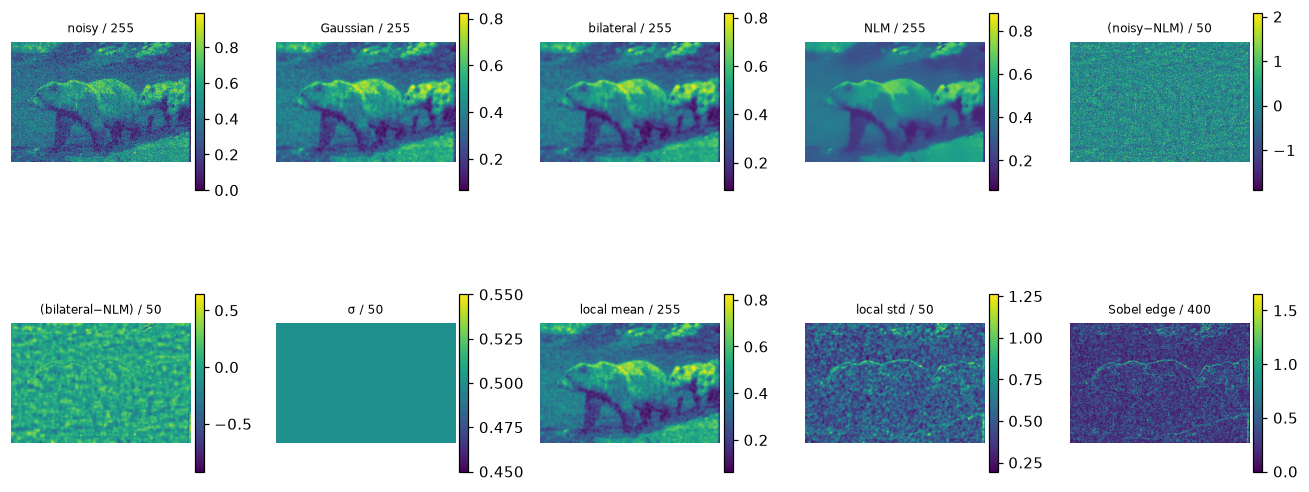

In [3]:
feature_names = ["noisy / 255", "Gaussian / 255", "bilateral / 255", "NLM / 255",
                 "(noisy−NLM) / 50", "(bilateral−NLM) / 50", "σ / 50",
                 "local mean / 255", "local std / 50", "Sobel edge / 400"]
x = features(outputs, sigma, include_texture=True)
assert x.shape == (clean.size, 10)
fig, axes = plt.subplots(2, 5, figsize=(12, 5.7))
for k, ax in enumerate(axes.flat):
    layer = x[:, k].reshape(clean.shape)
    im = ax.imshow(layer, cmap="viridis")
    ax.set_title(feature_names[k], fontsize=8)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=.046, pad=.02)
fig.tight_layout(); fig.savefig(FIG / "eda_feature_maps.png", dpi=160); plt.show()

## Residual target and actual MLP correction

The MLP learns `(reference − NLM)/255` from train pixels. The network is `10 inputs → 32 ReLU units → 1 correction`, with normalization learned on train, Adam, and 12 epochs. This is a small model trained from scratch; there is no pretrained checkpoint to fine-tune.

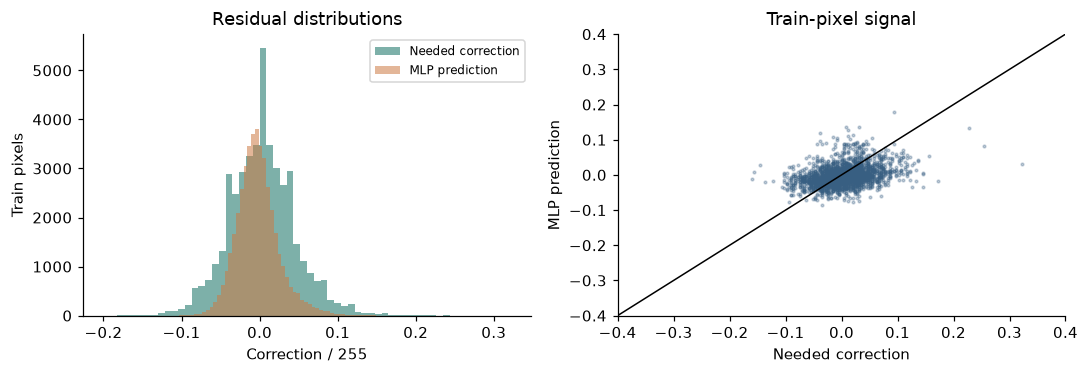

Residual target SD: 0.0429 | prediction SD: 0.0273


In [4]:
target = (clean.astype(np.float32) - outputs["nlm"].astype(np.float32)).ravel() / 255
pred = model.predict(x)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(target, bins=60, alpha=.55, label="Needed correction", color="#136f63")
axes[0].hist(pred, bins=60, alpha=.55, label="MLP prediction", color="#cc7b43")
axes[0].set(xlabel="Correction / 255", ylabel="Train pixels", title="Residual distributions")
axes[0].legend(fontsize=8)
idx = np.random.default_rng(SEED).choice(len(target), min(2500, len(target)), replace=False)
axes[1].scatter(target[idx], pred[idx], s=3, alpha=.3, c="#385f82")
axes[1].plot([-.4,.4],[-.4,.4], color="black", lw=1)
axes[1].set(xlim=(-.4,.4), ylim=(-.4,.4), xlabel="Needed correction", ylabel="MLP prediction", title="Train-pixel signal")
fig.tight_layout(); fig.savefig(FIG / "eda_residual_signal.png", dpi=160); plt.show()
print("Residual target SD:", round(float(target.std()), 4), "| prediction SD:", round(float(pred.std()), 4))

## Recorded model selection

The CSV below is the original validation search, and the weights were fitted on train. Do not pick a new setting from the final-test chart later in this notebook.

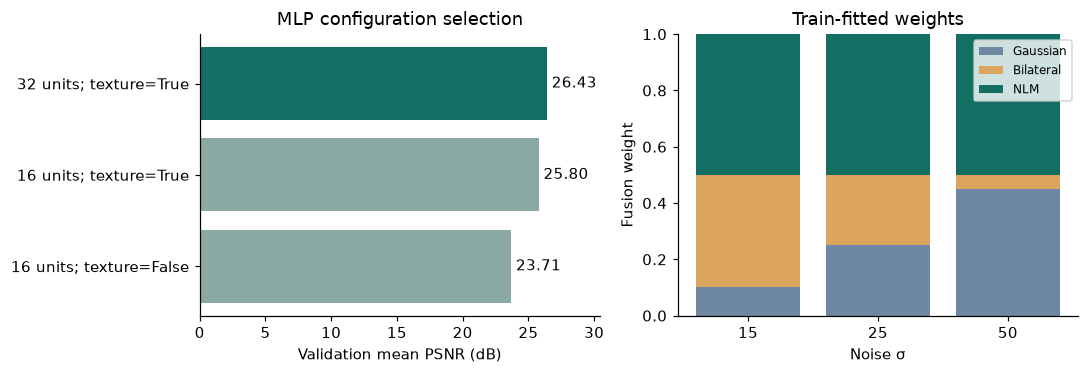

Selected validation configuration: (26.429795468865247, '32 units; texture=True')


In [5]:
with (ROOT / "results/model_selection.csv").open(newline="", encoding="utf-8") as f:
    selection = list(csv.DictReader(f))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
names = [f'{r["hidden"]} units; texture={r["texture"]}' for r in selection]
values = [float(r["val_mean_psnr_db"]) for r in selection]
bars = axes[0].barh(names, values, color=["#8ba9a4", "#8ba9a4", "#136f63"])
axes[0].bar_label(bars, fmt="%.2f", padding=3)
axes[0].set(xlim=(0, max(values)+4), xlabel="Validation mean PSNR (dB)", title="MLP configuration selection")
levels = [15,25,50]
colors = ["#6e88a4", "#dba55e", "#136f63"]
bottom = np.zeros(3)
for col, label, color in zip(range(3), ["Gaussian", "Bilateral", "NLM"], colors):
    vals = np.array([fusion[str(s)][col] for s in levels])
    axes[1].bar([str(s) for s in levels], vals, bottom=bottom, label=label, color=color)
    bottom += vals
axes[1].set(xlabel="Noise σ", ylabel="Fusion weight", ylim=(0,1), title="Train-fitted weights")
axes[1].legend(fontsize=8, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "eda_model_selection.png", dpi=160); plt.show()
print("Selected validation configuration:", max(zip(values, names)))

## Locked final-test results for interpretation only

This reads the existing saved `summary.csv`; it neither changes the model nor recomputes test predictions. The final test is 20 image IDs per σ. A larger PSNR means lower average squared pixel error; SSIM is a complementary structural score.

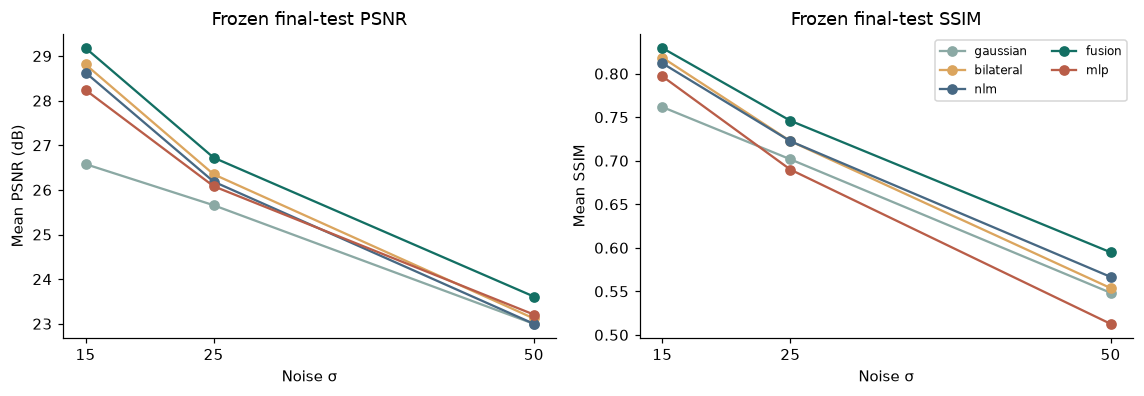

In [6]:
with (ROOT / "results/summary.csv").open(newline="", encoding="utf-8") as f:
    summary = list(csv.DictReader(f))
methods = ["gaussian", "bilateral", "nlm", "fusion", "mlp"]
levels = [15,25,50]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
palette = ["#8ba9a4", "#dba55e", "#476883", "#136f63", "#b95d48"]
for method, color in zip(methods, palette):
    rows = [next(r for r in summary if r["method"] == method and int(r["sigma"]) == s) for s in levels]
    axes[0].plot(levels, [float(r["mean_psnr_db"]) for r in rows], "o-", label=method, color=color)
    axes[1].plot(levels, [float(r["mean_ssim"]) for r in rows], "o-", label=method, color=color)
axes[0].set(xlabel="Noise σ", ylabel="Mean PSNR (dB)", title="Frozen final-test PSNR", xticks=levels)
axes[1].set(xlabel="Noise σ", ylabel="Mean SSIM", title="Frozen final-test SSIM", xticks=levels)
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(FIG / "eda_locked_test_results.png", dpi=160); plt.show()

## Findings and next step

The feature maps show what the model can see. They do not prove each channel helped. The validation ablation is the evidence for the texture-channel choice; the locked test scores show whether that choice generalized. The MLP remains a negative result against the fusion in this protocol. See `report/main.tex` for the scientific discussion and `docs/teach-me-like-grade-5.md` for a simpler explanation.